In [ ]:
!git clone https://github.com/pooja4730/churn-retention-strategy.git
%cd churn-retention-strategy
!pip install -q shap xgboost

import os
for d in ["models", "reports", "data"]:
    os.makedirs(d, exist_ok=True)
!ls data

Cloning into 'churn-retention-strategy'...
remote: Enumerating objects: 35, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (25/25), done.
remote: Total 35 (delta 7), reused 9 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (35/35), 454.12 KiB | 6.31 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/content/churn-retention-strategy/churn-retention-strategy
customers_scored.csv


In [21]:
import pandas as pd
from src.features import add_features

df = pd.read_csv("telco.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df = add_features(df)
df.to_csv("data/clean.csv", index=False)

print(df.shape)
!ls data

(7043, 26)
clean.csv  customers_scored.csv


In [22]:
!mv telco.csv data/telco.csv

In [31]:
import pandas as pd, numpy as np, joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

df = pd.read_csv("data/clean.csv")
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()

for col in cat_cols:
    X[col] = X[col].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             roc_auc_score, average_precision_score)

y_train_num = y_train
y_test_num = y_test

spw = (y_train_num == 0).sum() / (y_train_num == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             scale_pos_weight=spw, eval_metric="logloss",
                             random_state=42),
}

rows, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)])
    pipe.fit(X_train, y_train_num)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({"Model": name,
                 "Recall": recall_score(y_test_num, pred),
                 "Precision": precision_score(y_test_num, pred),
                 "F1": f1_score(y_test_num, pred),
                 "ROC-AUC": roc_auc_score(y_test_num, proba),
                 "PR-AUC": average_precision_score(y_test_num, proba)})
    fitted[name] = pipe

results = pd.DataFrame(rows).round(3)
results

,Model,Recall,Precision,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.783,0.512,0.619,0.846,0.657
1,Random Forest,0.463,0.588,0.518,0.820,0.612
2,XGBoost,0.797,0.532,0.638,0.842,0.656


In [ ]:
import os
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt
os.makedirs("../reports", exist_ok=True)

best_name = results.sort_values("ROC-AUC", ascending=False).iloc[0]["Model"]
best = fitted[best_name]
print("Best model:", best_name)

ConfusionMatrixDisplay.from_estimator(best, X_test, y_test_num, cmap="Blues")
plt.savefig("../reports/confusion.png", dpi=150); plt.show()

RocCurveDisplay.from_estimator(best, X_test, y_test_num)
plt.savefig("../reports/roc.png", dpi=150); plt.show()

In [35]:
print(type(best))
print(type(X_test), getattr(X_test, "shape", None))
print(type(y_test_num))

<class 'sklearn.pipeline.Pipeline'>
<class 'pandas.core.frame.DataFrame'> (1409, 24)
<class 'pandas.core.series.Series'>


In [36]:
import numpy as np

best_name = results.sort_values("ROC-AUC", ascending=False).iloc[0]["Model"]
best = fitted[best_name]                      # the Pipeline, not the name
y_test_num = y_test.astype(int).values        # 0/1 numbers

COST_MISS, COST_OFFER, SUCCESS = 1000, 150, 0.30

proba = best.predict_proba(X_test)[:, 1]
best_t, best_profit = 0.5, -1e9
for t in np.arange(0.1, 0.9, 0.05):
    flagged = proba >= t
    saved = (flagged & (y_test_num == 1)).sum() * SUCCESS * COST_MISS
    profit = saved - flagged.sum() * COST_OFFER
    if profit > best_profit:
        best_t, best_profit = t, profit

print("Best model:", best_name)
print("Best threshold:", round(best_t, 2), "| Net benefit: Rs", round(best_profit))

Best model: Logistic Regression
Best threshold: 0.75 | Net benefit: Rs 14700


In [37]:
COST_MISS = 1000
COST_OFFER = 150
SUCCESS = 0.30

proba = best.predict_proba(X_test)[:, 1]
best_t, best_profit = 0.5, -1e9
for t in np.arange(0.1, 0.9, 0.05):
    flagged = proba >= t
    saved = ((flagged) & (y_test_num == 1)).sum() * SUCCESS * COST_MISS
    spent = flagged.sum() * COST_OFFER
    profit = saved - spent
    if profit > best_profit:
        best_t, best_profit = t, profit
print("Best threshold:", round(best_t, 2), "| Net benefit (test set): Rs", round(best_profit))

Best threshold: 0.75 | Net benefit (test set): Rs 14700


In [ ]:
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(best, "../models/churn_model.joblib")
joblib.dump(best_t, "../models/threshold.joblib")

In [39]:
print(best_name)
print(type(clf))

Logistic Regression
<class 'sklearn.linear_model._logistic.LogisticRegression'>


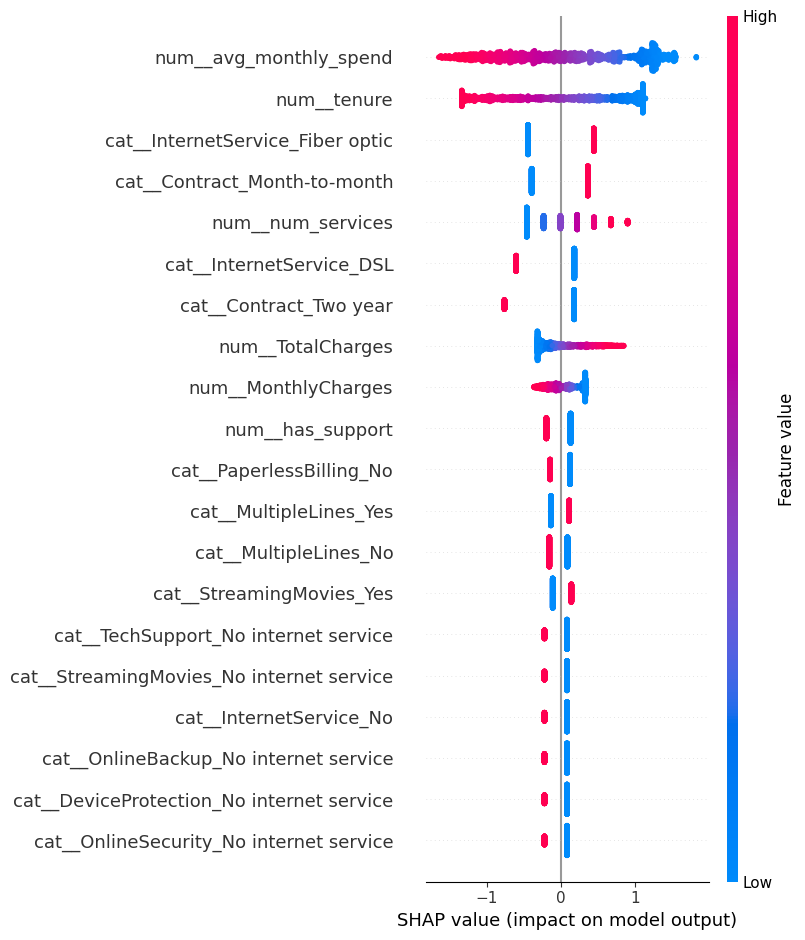

In [44]:
import shap, matplotlib.pyplot as plt

pre = best.named_steps["prep"]
clf = best.named_steps["model"]
Xt_train = pre.transform(X_train)
Xt = pre.transform(X_test)
names = pre.get_feature_names_out()

explainer = shap.LinearExplainer(clf, Xt_train)
sv = explainer.shap_values(Xt)

shap.summary_plot(sv, Xt, feature_names=names, show=False)
plt.savefig("reports/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

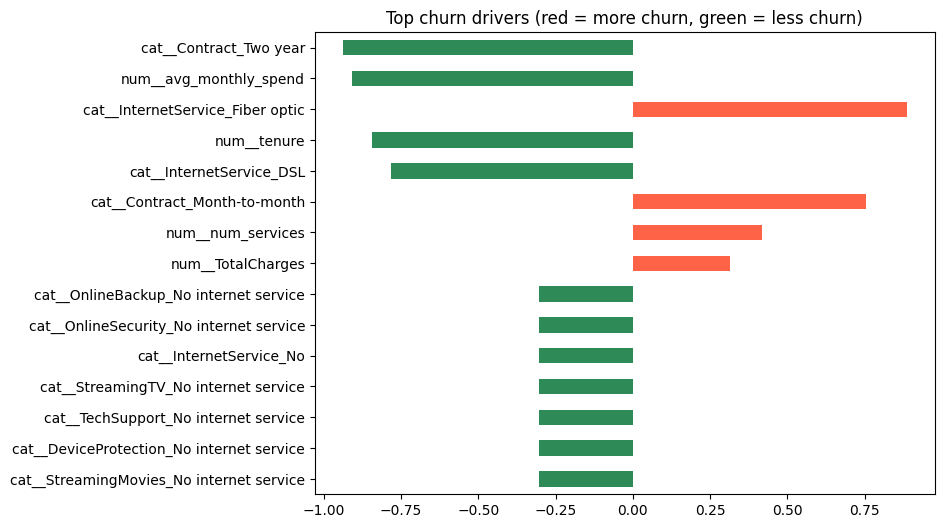

In [45]:
import pandas as pd

coef = pd.Series(clf.coef_[0], index=names).sort_values(key=abs, ascending=False).head(15)
colors = ["tomato" if v > 0 else "seagreen" for v in coef]
coef.plot(kind="barh", color=colors, figsize=(8, 6)).invert_yaxis()
plt.title("Top churn drivers (red = more churn, green = less churn)")
plt.savefig("reports/top_drivers.png", dpi=150, bbox_inches="tight")
plt.show()

In [46]:
import joblib, sklearn, xgboost, shap, pandas, numpy

joblib.dump(best, "models/churn_model.joblib")
joblib.dump(float(best_t), "models/threshold.joblib")

open("requirements.txt", "w").write(
f"""pandas=={pandas.__version__}
numpy=={numpy.__version__}
scikit-learn=={sklearn.__version__}
xgboost=={xgboost.__version__}
shap=={shap.__version__}
streamlit
joblib
""")

!ls models reports data

data:
clean.csv  customers_scored.csv  telco.csv

models:
best_model.joblib  churn_model.joblib  threshold.joblib

reports:
shap_summary.png  top_drivers.png


In [47]:
from getpass import getpass
token = getpass("Paste GitHub token: ")

!git config --global user.email "poojagosavi473@gmail.com"
!git config --global user.name "Pooja Gosavi"
!echo "__pycache__/" > .gitignore
!git add .
!git status
!git commit -m "Add Logistic Regression model, SHAP and charts"
!git push https://{token}@github.com/pooja4730/churn-retention-strategy.git main

Paste GitHub token: ··········
On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   data/clean.csv
	renamed:    telco.csv -> data/telco.csv
	new file:   models/churn_model.joblib
	new file:   models/threshold.joblib
	new file:   reports/shap_summary.png
	new file:   reports/top_drivers.png

[main f62596a] Add Logistic Regression model, SHAP and charts
 6 files changed, 7044 insertions(+)
 create mode 100644 data/clean.csv
 rename telco.csv => data/telco.csv (100%)
 create mode 100644 models/churn_model.joblib
 create mode 100644 models/threshold.joblib
 create mode 100644 reports/shap_summary.png
 create mode 100644 reports/top_drivers.png
To https://github.com/pooja4730/churn-retention-strategy.git
 ! [rejected]        main -> main (fetch first)
error: failed to push some refs to 'https://github.com/pooja4730/churn-retention-strategy.git'
hint: Updates were rejected because the remote co